<a href="https://colab.research.google.com/github/ZikriAzzuri5/Social_Media_Behavior_-_Productivity_Analysis/blob/main/Social_Media_Behavior_%26_Productivity_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Social Media Behavior & Productivity Analysis

Analisis hubungan antara perilaku penggunaan media sosial dengan produktivitas,
menggunakan dataset sintetis dari Kaggle (300 partisipan).

**Catatan:** Dataset ini 100% synthetic_ai, dan 8 pertanyaan riset diadaptasi
dari "Potential Research Questions" yang disarankan pembuat dataset di Kaggle.

Sumber: https://www.kaggle.com/datasets/manaswinsripatnala/social-media-dopamine-and-productivity-dataset

In [ ]:
!pip install scikit-posthocs
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
import seaborn as sns
from scipy.stats import shapiro
import scikit_posthocs as sp
from scipy.stats import chi2_contingency



import numpy as np

df = pd.read_csv('sosmed.csv', keep_default_na=False)

## Data Overview


In [ ]:
df.head(5)

,participant_id,data_source,synthetic_flag,age,age_group,gender,race_ethnicity,nationality,country_of_residence,education_level,...,mood_dependency_on_sm,withdrawal_attempt_count,longest_detox_days,detox_relapse_reason,severity_stage,productivity_decline_score,dopamine_dysregulation_index,digital_wellbeing_score,sm_addiction_risk_score,notes
0,P0001,synthetic_ai,1,16,13-17,Female,South Asian,Indian,India,High school,...,Yes,9,2,3,Boredom,Critical,8.8,9.2,2.1,9.5
1,P0002,synthetic_ai,1,17,13-17,Male,East Asian,Chinese,China,High school,...,Yes,10,1,1,Curiosity,Critical,9.5,9.8,1.5,9.8
2,P0003,synthetic_ai,1,15,13-17,Female,Black/African,Nigerian,Nigeria,High school,...,Yes,8,2,5,Boredom,Severe,8.0,8.5,2.8,9.0
3,P0004,synthetic_ai,1,19,18-22,Male,White/Caucasian,American,USA,High school,...,Yes,9,3,7,Boredom,Severe,7.8,8.2,2.9,8.8
4,P0005,synthetic_ai,1,18,18-22,Female,Hispanic/Latino,Mexican,Mexico,High school,...,Yes,9,2,4,FOMO,Critical,9.0,9.3,2.0,9.6


In [ ]:
df.describe()

,synthetic_flag,age,avg_daily_sm_hours,years_on_social_media,avg_daily_screen_time_hours,avg_sleep_hours,avg_work_study_hours_per_day,dopamine_rush_feel_score,reward_seeking_behavior,fomo_score,...,decision_fatigue_score,anxiety_when_phone_unavailable,restlessness_score,withdrawal_attempt_count,longest_detox_days,detox_relapse_reason,dopamine_dysregulation_index,digital_wellbeing_score,sm_addiction_risk_score,notes
count,300.0,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,...,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,1.0,36.310000,4.030000,7.503333,7.830000,7.325000,7.100000,4.920000,2.556667,4.590000,...,3.963333,4.300000,4.143333,4.283333,5.413333,28.740000,4.354333,4.853667,6.170333,5.006000
std,0.0,15.175029,2.034181,2.690872,2.271556,1.033005,2.673417,2.490168,1.308624,2.142553,...,2.414142,2.792129,2.610012,2.925449,2.575123,23.587999,2.750095,2.692319,2.649709,2.922093
min,1.0,15.000000,0.500000,3.000000,3.000000,4.500000,0.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.500000,1.000000,1.100000,0.500000
25%,1.0,24.000000,2.500000,5.000000,6.375000,6.875000,6.000000,3.000000,1.000000,3.000000,...,2.000000,2.000000,2.000000,2.000000,3.000000,10.000000,1.800000,2.400000,4.200000,2.200000
50%,1.0,33.500000,3.500000,8.000000,7.500000,7.500000,8.000000,4.000000,2.000000,4.000000,...,3.000000,3.000000,3.500000,3.000000,6.000000,24.000000,3.200000,3.800000,7.000000,4.000000
75%,1.0,46.250000,5.500000,10.000000,9.500000,8.000000,9.000000,7.000000,3.000000,6.000000,...,5.000000,7.000000,6.000000,7.000000,8.000000,48.000000,6.200000,6.800000,8.800000,7.200000
max,1.0,75.000000,9.000000,14.000000,13.000000,9.000000,9.500000,10.000000,5.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,90.000000,9.900000,10.000000,9.900000,10.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 66 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   participant_id                    300 non-null    object 
 1   data_source                       300 non-null    object 
 2   synthetic_flag                    300 non-null    int64  
 3   age                               300 non-null    int64  
 4   age_group                         300 non-null    object 
 5   gender                            300 non-null    object 
 6   race_ethnicity                    300 non-null    object 
 7   nationality                       300 non-null    object 
 8   country_of_residence              300 non-null    object 
 9   education_level                   300 non-null    object 
 10  employment_status                 300 non-null    object 
 11  occupation_category               300 non-null    object 
 12  relation

In [ ]:
df['productivity_self_rating'].equals(df['work_quality_self_rating'])
df = df.drop(columns=['work_quality_self_rating'])

## Rencana Analisis per Pertanyaan

| # | Pertanyaan Riset | Variabel Utama |
|---|---|---|
| Q1 | Apakah penggunaan SM tinggi berasosiasi dengan produktivitas rendah? | avg_daily_sm_hours vs productivity_self_rating |
| Q2 | Bagaimana frekuensi cek SM berhubungan dengan attention span? | daily_check_frequency vs attention_span_minutes |
| Q3 | Apakah scrolling larut malam berasosiasi dengan kualitas tidur? | late_night_scrolling vs sleep_quality |
| Q4 | Apakah SM saat kerja/belajar berhubungan dengan task switching? | sm_during_work_study vs task_switching_frequency |
| Q5 | Bagaimana FOMO, validation-seeking, dan reward-seeking berhubungan dengan produktivitas? | fomo_score, validation_seeking_score, reward_seeking_behavior vs productivity_self_rating |
| Q6 | Faktor perilaku apa yang berasosiasi dengan risiko adiksi SM? | dopamine_rush_feel_score, boredom_to_phone_reflex, inability_to_delay_gratification, notifications_always_on vs sm_addiction_risk_score |
| Q7 | Apakah digital wellbeing berasosiasi dengan produktivitas dan deep-work? | digital_wellbeing_score vs productivity_self_rating, deep_work_duration_minutes |
| Q8 | Dapatkah perilaku SM memprediksi penurunan produktivitas? | sm_addiction_risk_score → productivity_decline_score (binary) |

*Catatan: 8 pertanyaan ini diadaptasi dari "Potential Research Questions" pada deskripsi dataset di Kaggle.*

## Data Quality Findings

Sebelum masuk ke analisis, ditemukan beberapa isu kualitas data penting:

- **Data sintetis**: kolom `data_source` menunjukkan 100% data adalah `synthetic_ai` — bukan data manusia riil, sehingga kekuatan korelasi yang ditemukan sepanjang analisis ini tidak dapat digeneralisasi ke populasi nyata.
- **Kolom duplikat**: `work_quality_self_rating` identik 100% dengan `productivity_self_rating` (dibuktikan via `.equals()`), sehingga di-drop dari dataset.
- **Missing value semu**: kolom `severity_stage` dan `secondary_platform` awalnya terbaca sebagian missing oleh `pd.read_csv()` default. Setelah dicek ulang dengan `keep_default_na=False`, terbukti nilai seperti `"N/A"` dan `"None"` adalah **kategori bermakna** (bukan data kosong), sehingga file di-load dengan `keep_default_na=False` sejak awal.

## Q1: Apakah penggunaan media sosial tinggi berasosiasi dengan produktivitas rendah?

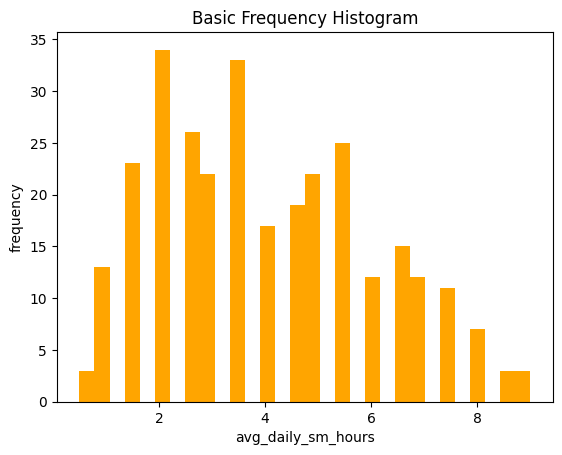

In [ ]:
subset_q1 = df[['avg_daily_sm_hours', 'productivity_self_rating']].dropna()
plt.hist(subset_q1['avg_daily_sm_hours'], bins=30, color=['orange'])
plt.title('Basic Frequency Histogram')
plt.xlabel('avg_daily_sm_hours')
plt.ylabel('frequency')
plt.show()

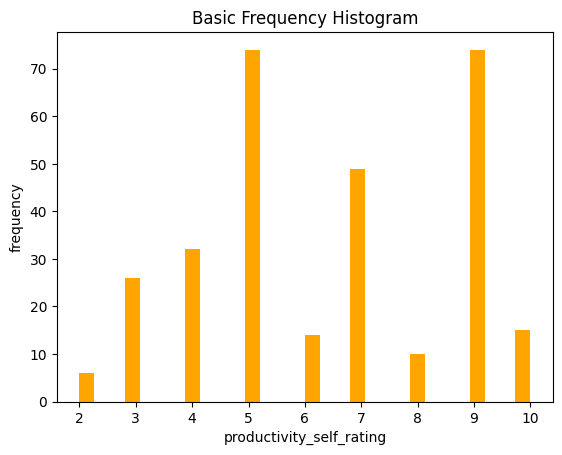

In [ ]:
plt.hist(subset_q1['productivity_self_rating'], bins=30, color=['orange'])
plt.title('Basic Frequency Histogram')
plt.xlabel('productivity_self_rating')
plt.ylabel('frequency')
plt.show()

In [ ]:
statistic, p_value = stats.shapiro(subset_q1['avg_daily_sm_hours'])
print(f"Shapiro-Wilk Statistic avg_daily_sm_hours: {statistic:.4f}")
print(f"p-value: {p_value:.4f}")
alpha = 0.05
if p_value > alpha:
    print("Result: Fail to reject the null hypothesis. The data appears to be normally distributed.")
else:
    print("Result: Reject the null hypothesis. The data does not follow a normal distribution.")


Shapiro-Wilk Statistic avg_daily_sm_hours: 0.9594
p-value: 0.0000
Result: Reject the null hypothesis. The data does not follow a normal distribution.


In [ ]:
statistic, p_value = stats.shapiro(subset_q1['productivity_self_rating'])
print(f"Shapiro-Wilk Statistic productivity_self_rating: {statistic:.4f}")
print(f"p-value: {p_value:.4f}")
alpha = 0.05
if p_value > alpha:
    print("Result: Fail to reject the null hypothesis. The data appears to be normally distributed.")
else:
    print("Result: Reject the null hypothesis. The data does not follow a normal distribution.")


Shapiro-Wilk Statistic productivity_self_rating: 0.9160
p-value: 0.0000
Result: Reject the null hypothesis. The data does not follow a normal distribution.


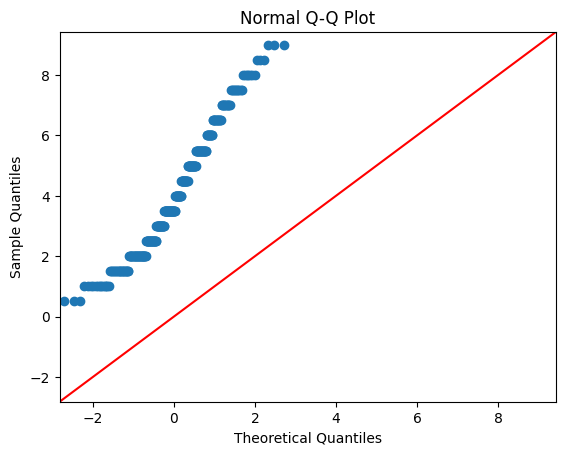

In [ ]:
sm.qqplot(subset_q1['avg_daily_sm_hours'], line='45')
plt.title("Normal Q-Q Plot")
plt.show()


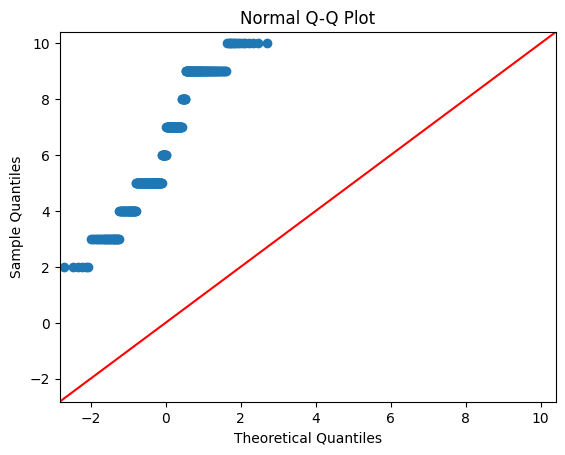

In [ ]:
sm.qqplot(subset_q1['productivity_self_rating'], line='45')
plt.title("Normal Q-Q Plot")
plt.show()


Spearman's rho: -0.9782
p-value: 0.0000


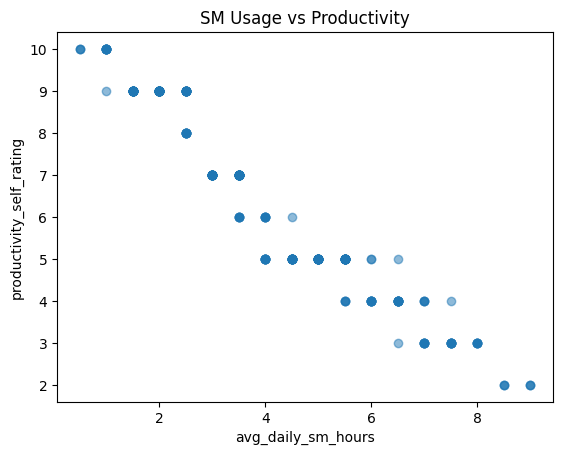

In [ ]:
rho, p_value = stats.spearmanr(subset_q1['avg_daily_sm_hours'], subset_q1['productivity_self_rating'])
print(f"Spearman's rho: {rho:.4f}")
print(f"p-value: {p_value:.4f}")
plt.scatter(subset_q1['avg_daily_sm_hours'], subset_q1['productivity_self_rating'], alpha=0.5)
plt.xlabel('avg_daily_sm_hours')
plt.ylabel('productivity_self_rating')
plt.title('SM Usage vs Productivity')
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

u_stat, p_value_mw = mannwhitneyu(grup_rendah, grup_tinggi)
print(f"U-statistic: {u_stat:.4f}")
print(f"p-value: {p_value_mw:.4f}")

U-statistic: 22460.0000
p-value: 0.0000


In [ ]:
  median_sm = subset_q1['avg_daily_sm_hours'].median()
  grup_rendah = subset_q1[subset_q1['avg_daily_sm_hours'] <= median_sm]['productivity_self_rating']
  grup_tinggi = subset_q1[subset_q1['avg_daily_sm_hours'] > median_sm]['productivity_self_rating']
  print(len(grup_rendah))
  print(len(grup_tinggi))

154
146


/tmp/ipykernel_4202/2267201996.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='grup', y='productivity_self_rating', data=df_q1_long, palette='Set2')


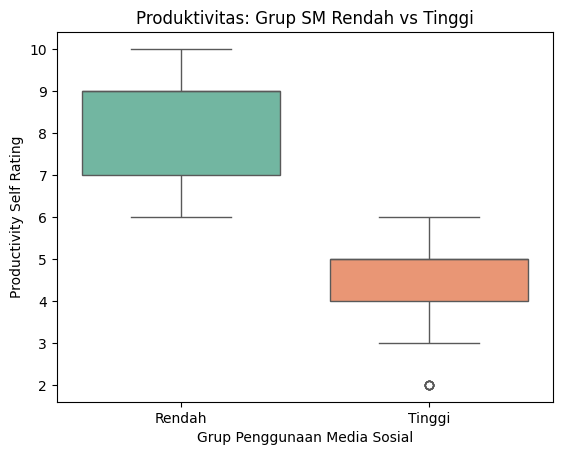

In [ ]:
df_rendah = grup_rendah.to_frame(name='productivity_self_rating')
df_rendah['grup'] = 'Rendah'

df_tinggi = grup_tinggi.to_frame(name='productivity_self_rating')
df_tinggi['grup'] = 'Tinggi'

df_q1_long = pd.concat([df_rendah, df_tinggi], ignore_index=True)

sns.boxplot(x='grup', y='productivity_self_rating', data=df_q1_long, palette='Set2')
plt.title('Produktivitas: Grup SM Rendah vs Tinggi')
plt.xlabel('Grup Penggunaan Media Sosial')
plt.ylabel('Productivity Self Rating')
plt.show()

In [ ]:
n1 = len(grup_rendah)
n2 = len(grup_tinggi)
rank_biserial = 1 - (2 * u_stat) / (n1 * n2)
print(f"Rank-biserial correlation (effect size): {rank_biserial:.4f}")

Rank-biserial correlation (effect size): -0.9979


### Kesimpulan Q1

Terdapat asosiasi negatif yang sangat kuat antara durasi penggunaan media sosial
harian dan rating produktivitas diri (Spearman's rho = -0.98, p < 0.001). Median
split mengonfirmasi ini: grup pengguna SM rendah memiliki median produktivitas
jauh lebih tinggi dibanding grup pengguna SM tinggi (Mann-Whitney U, p < 0.001,
rank-biserial r ≈ -0.998). Kekuatan efek yang mendekati sempurna ini melampaui
apa yang biasa ditemukan pada data perilaku manusia riil, dan kemungkinan besar
mencerminkan pola yang sengaja dibuat dalam proses generate data sintetis.

## Q2: Bagaimana frekuensi cek media sosial berhubungan dengan attention span?

In [ ]:
subset_q2 = df[['attention_span_minutes', 'daily_check_frequency']].dropna()

stat, p = shapiro(subset_q2['attention_span_minutes'])
print(f"Shapiro-Wilk Statistic attention_span_minutes: {stat:.4f}")
print(f"p-value: {p:.4f}")


Shapiro-Wilk Statistic attention_span_minutes: 0.9212
p-value: 0.0000


In [ ]:
print(subset_q2['daily_check_frequency'].unique())

kat_uniq = subset_q2['daily_check_frequency'].unique()
grup_list = [subset_q2[subset_q2['daily_check_frequency'] == kat]['attention_span_minutes']
             for kat in kat_uniq]
statistic, p_value = stats.levene(*grup_list, center='median')

print(f"Levene's Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")




['Constantly' 'Every few hours' '2-3 times a day' 'Once a day'
 'Once a week']
Levene's Statistic: 0.9212
P-value: 0.0000


In [ ]:
kruskal_stat, p_value_kw = stats.kruskal(*grup_list)
print(f"Kruskal-Wallis Statistic: {kruskal_stat:.4f}")
print(f"p-value: {p_value_kw:.4f}")

Kruskal-Wallis Statistic: 269.2928
p-value: 0.0000


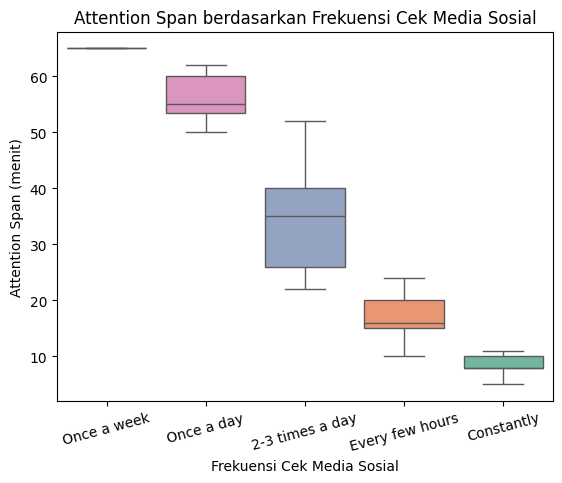

In [ ]:
urutan_kategori = ['Once a week', 'Once a day', '2-3 times a day', 'Every few hours', 'Constantly']
sns.boxplot(x='daily_check_frequency', y='attention_span_minutes',
            data=subset_q2, order=urutan_kategori,
            hue='daily_check_frequency', palette='Set2', legend=False)
plt.title('Attention Span berdasarkan Frekuensi Cek Media Sosial')
plt.xlabel('Frekuensi Cek Media Sosial')
plt.ylabel('Attention Span (menit)')
plt.xticks(rotation=15)
plt.show()

In [ ]:
p_values = sp.posthoc_dunn(subset_q2, val_col='attention_span_minutes', group_col='daily_check_frequency', p_adjust='holm')
print(p_values)


                 2-3 times a day    Constantly  Every few hours    Once a day  \
2-3 times a day     1.000000e+00  1.794893e-32     7.596344e-19  3.489519e-05   
Constantly          1.794893e-32  1.000000e+00     7.913974e-06  8.480776e-39   
Every few hours     7.596344e-19  7.913974e-06     1.000000e+00  7.571192e-26   
Once a day          3.489519e-05  8.480776e-39     7.571192e-26  1.000000e+00   
Once a week         1.294318e-01  6.178603e-07     2.229316e-04  7.131612e-01   

                  Once a week  
2-3 times a day  1.294318e-01  
Constantly       6.178603e-07  
Every few hours  2.229316e-04  
Once a day       7.131612e-01  
Once a week      1.000000e+00  


### Kesimpulan Q2

Frekuensi pengecekan media sosial berasosiasi kuat dan signifikan dengan attention
span (Kruskal-Wallis H=269.29, p<0.001), dengan pola penurunan yang konsisten
seiring meningkatnya frekuensi cek. Uji post-hoc Dunn mengonfirmasi perbedaan
signifikan pada hampir seluruh pasangan kategori (9 dari 10 pasangan), kecuali
yang melibatkan kategori "Once a week" (n=3) — kemungkinan besar karena ukuran
sampel yang sangat kecil sehingga uji statistik kurang memiliki power untuk
mendeteksi perbedaan, bukan indikasi tidak adanya perbedaan sesungguhnya.

## Q3: Apakah scrolling larut malam berasosiasi dengan kualitas tidur?

In [ ]:
subset_q3 = df[['late_night_scrolling', 'sleep_quality']].dropna()

chi2, p_value, dof, expected = chi2_contingency(pd.crosstab(subset_q3['late_night_scrolling'], subset_q3['sleep_quality']))
print(f"Chi-squared Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")
print("Expected Frequencies:")
print(expected)

Chi-squared Statistic: 531.1202
P-value: 0.0000
Degrees of Freedom: 16
Expected Frequencies:
[[18.         35.04       10.32        6.24        2.4       ]
 [ 7.25       14.11333333  4.15666667  2.51333333  0.96666667]
 [ 7.5        14.6         4.3         2.6         1.        ]
 [20.75       40.39333333 11.89666667  7.19333333  2.76666667]
 [21.5        41.85333333 12.32666667  7.45333333  2.86666667]]


In [ ]:
print(df['sleep_quality'].value_counts())
print(df['late_night_scrolling'].value_counts())

sleep_quality
Good         146
Fair          75
Poor          43
Very good     26
Very poor     10
Name: count, dtype: int64
late_night_scrolling
Sometimes    86
Rarely       83
Daily        72
Often        30
Never        29
Name: count, dtype: int64


In [ ]:
mapping_sleep = {'Very poor': 1, 'Poor': 2, 'Fair': 3, 'Good': 4, 'Very good': 5}
mapping_scrolling = {'Never': 1, 'Rarely': 2, 'Sometimes': 3, 'Often': 4, 'Daily': 5}

subset_q3['sleep_quality_encoded'] = subset_q3['sleep_quality'].map(mapping_sleep)
subset_q3['late_night_scrolling_encoded'] = subset_q3['late_night_scrolling'].map(mapping_scrolling)

res = stats.spearmanr(subset_q3['sleep_quality_encoded'], subset_q3['late_night_scrolling_encoded'])
print("Correlation:", res.statistic)
print("P-value:", res.pvalue)

Correlation: -0.8874596636838687
P-value: 2.9283750081508573e-102


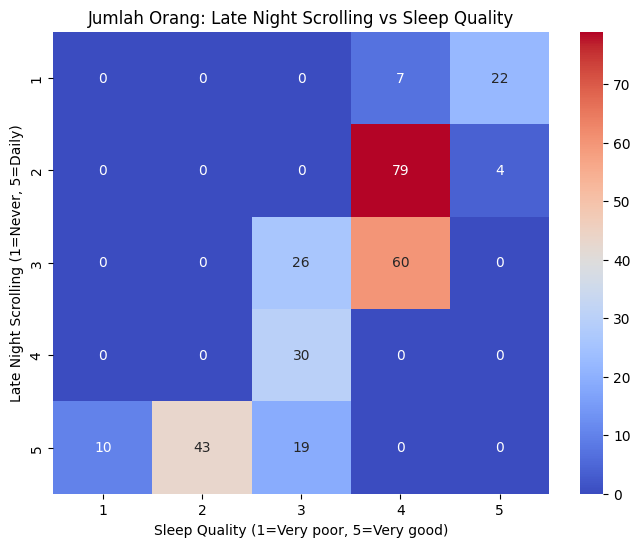

In [ ]:
plt.figure(figsize=(8, 6))
crosstab_q3 = pd.crosstab(subset_q3['late_night_scrolling_encoded'], subset_q3['sleep_quality_encoded'])
sns.heatmap(crosstab_q3, annot=True, cmap='coolwarm', fmt='d')
plt.title('Jumlah Orang: Late Night Scrolling vs Sleep Quality')
plt.xlabel('Sleep Quality (1=Very poor, 5=Very good)')
plt.ylabel('Late Night Scrolling (1=Never, 5=Daily)')
plt.show()

### Kesimpulan Q3

Terdapat asosiasi negatif yang sangat kuat antara frekuensi scrolling larut malam
dan kualitas tidur (Spearman's rho=-0.887, p<0.001), dikonfirmasi juga oleh uji
Chi-square (χ²=531.12, p<0.001). Visualisasi crosstab menunjukkan pola yang sangat
konsisten: tidak ada partisipan yang jarang scrolling malam namun memiliki kualitas
tidur buruk, dan sebaliknya tidak ada yang sering scrolling (Daily) namun kualitas
tidurnya baik. Seperti pada Q1 dan Q2, kekuatan hubungan yang mendekati sempurna
ini kemungkinan mencerminkan karakteristik data sintetis.

## Q4: Apakah penggunaan SM saat kerja/belajar berhubungan dengan task switching?

In [ ]:
subset_q4 = df[['sm_during_work_study', 'task_switching_frequency']].dropna()
print(df['sm_during_work_study'].value_counts())
print(df['task_switching_frequency'].value_counts())

sm_during_work_study
Sometimes    100
Rarely        68
Often         67
Always        37
Never         28
Name: count, dtype: int64
task_switching_frequency
Low         160
Moderate     75
High         65
Name: count, dtype: int64


In [ ]:
chi2, p_value, dof, expected = chi2_contingency(pd.crosstab(subset_q4['sm_during_work_study'], subset_q4['task_switching_frequency']))
print(f"Chi-squared Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")
print("Expected Frequencies:")
print(expected)

Chi-squared Statistic: 324.2221
P-value: 0.0000
Degrees of Freedom: 8
Expected Frequencies:
[[ 8.01666667 19.73333333  9.25      ]
 [ 6.06666667 14.93333333  7.        ]
 [14.51666667 35.73333333 16.75      ]
 [14.73333333 36.26666667 17.        ]
 [21.66666667 53.33333333 25.        ]]


In [ ]:
mapping_sm_during_work_study = {'Never': 1, 'Rarely': 2, 'Sometimes': 3, 'Often': 4, 'Always': 5}
mapping_task_switching_frequency = {'Low': 1, 'Moderate': 2, 'High': 3}

subset_q4['sm_during_work_study_encoded'] = subset_q4['sm_during_work_study'].map(mapping_sm_during_work_study)
subset_q4['task_switching_frequency_encoded'] = subset_q4['task_switching_frequency'].map(mapping_task_switching_frequency)

res = stats.spearmanr(subset_q4['sm_during_work_study_encoded'], subset_q4['task_switching_frequency_encoded'])
print("Correlation:", res.statistic)
print("P-value:", res.pvalue)

Correlation: 0.8488113538621532
P-value: 1.7801288045120992e-84


task_switching_frequency_encoded   1   2   3
sm_during_work_study_encoded                
1                                 28   0   0
2                                 68   0   0
3                                 64  36   0
4                                  0  39  28
5                                  0   0  37


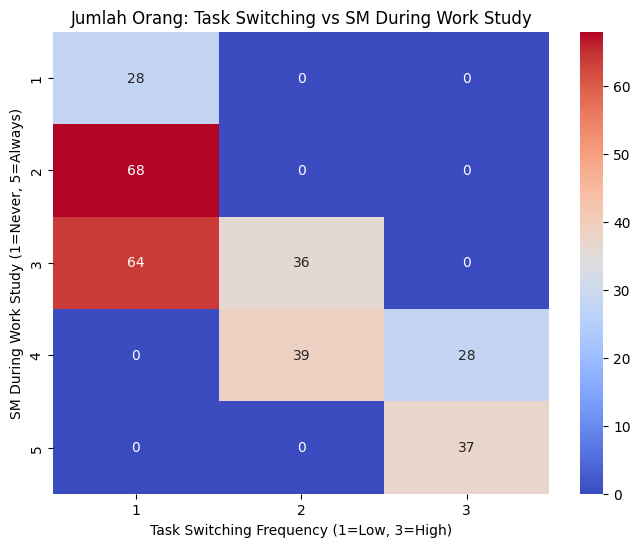

In [ ]:
plt.figure(figsize=(8, 6))
crosstab_q4 = pd.crosstab(subset_q4['sm_during_work_study_encoded'], subset_q4['task_switching_frequency_encoded'])
print(crosstab_q4)
sns.heatmap(crosstab_q4, annot=True, cmap='coolwarm', fmt='d')
plt.title('Jumlah Orang: Task Switching vs SM During Work Study')
plt.ylabel('SM During Work Study (1=Never, 5=Always)')
plt.xlabel('Task Switching Frequency (1=Low, 3=High)')
plt.show()

### Kesimpulan Q4

Terdapat asosiasi positif yang sangat kuat antara frekuensi penggunaan media sosial
saat bekerja/belajar dan frekuensi task switching (Spearman's rho=0.849, p<0.001).
Visualisasi crosstab menunjukkan pola diagonal yang konsisten: partisipan dengan
penggunaan SM rendah-menengah saat kerja/belajar selalu berada di kategori task
switching "Low", sementara partisipan dengan penggunaan SM tinggi berada di
kategori "Moderate" hingga "High". Konsisten dengan Q1-Q3, kekuatan hubungan yang
mendekati sempurna ini kemungkinan mencerminkan karakteristik data sintetis.

## Q5: Bagaimana FOMO, validation seeking, dan reward-seeking berhubungan dengan produktivitas?

In [ ]:
subset_q5 = df[['fomo_score', 'validation_seeking_score', 'reward_seeking_behavior', 'productivity_self_rating']].dropna()
for col in subset_q5.columns:
    statistic, p_value = stats.shapiro(subset_q5[col])
    print(f"Shapiro-Wilk Statistic {col}: {statistic:.4f}")
    print(f"p-value: {p_value:.4f}")
alpha = 0.05
if p_value > alpha:
    print("Result: Fail to reject the null hypothesis. The data appears to be normally distributed.")
else:
    print("Result: Reject the null hypothesis. The data does not follow a normal distribution.")

Shapiro-Wilk Statistic fomo_score: 0.9568
p-value: 0.0000
Shapiro-Wilk Statistic validation_seeking_score: 0.9122
p-value: 0.0000
Shapiro-Wilk Statistic reward_seeking_behavior: 0.8791
p-value: 0.0000
Shapiro-Wilk Statistic productivity_self_rating: 0.9160
p-value: 0.0000
Result: Reject the null hypothesis. The data does not follow a normal distribution.


In [ ]:
spearman_matrix = subset_q5.corr(method='spearman')
print(spearman_matrix)

                          fomo_score  validation_seeking_score  \
fomo_score                  1.000000                  0.991448   
validation_seeking_score    0.991448                  1.000000   
reward_seeking_behavior     0.962934                  0.967747   
productivity_self_rating   -0.979655                 -0.974630   

                          reward_seeking_behavior  productivity_self_rating  
fomo_score                               0.962934                 -0.979655  
validation_seeking_score                 0.967747                 -0.974630  
reward_seeking_behavior                  1.000000                 -0.960337  
productivity_self_rating                -0.960337                  1.000000  


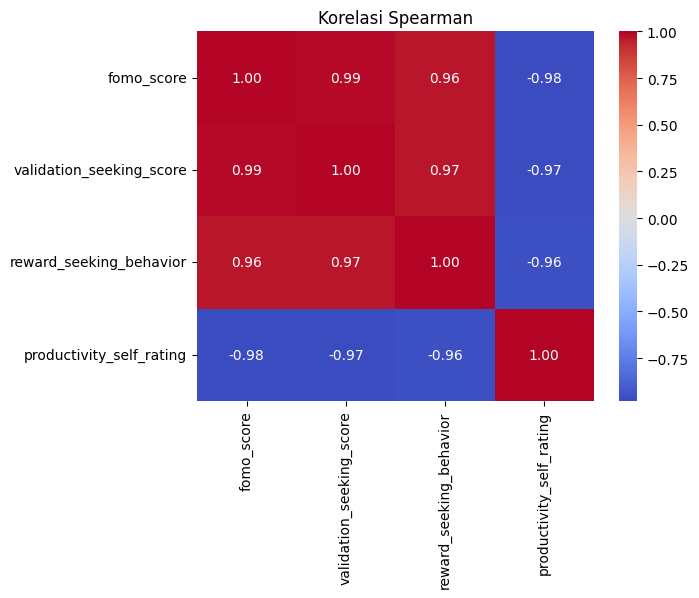

In [ ]:
sns.heatmap(spearman_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Spearman')
plt.show()

### Kesimpulan Q5

Ketiga faktor psikologis (FOMO, validation-seeking, reward-seeking) menunjukkan
korelasi negatif yang sangat kuat dengan produktivitas (Spearman's rho -0.96
hingga -0.98, semua p<0.001). Namun, ditemukan multicollinearity ekstrem di antara
ketiga prediktor ini (korelasi antar-prediktor 0.96-0.99, terlihat di heatmap),
sehingga regresi berganda TIDAK dijalankan — interpretasi koefisien individual
berisiko menyesatkan dalam kondisi ini. Korelasi bivariat dipilih sebagai
pendekatan yang lebih andal.

## Q6: Faktor perilaku apa yang berasosiasi dengan risiko adiksi media sosial?

**Validasi arah skala `sm_addiction_risk_score` terlebih dahulu:**

In [ ]:
print(df.groupby('severity_stage')['sm_addiction_risk_score'].mean().sort_values())

                                          dopamine_rush_feel_score  \
dopamine_rush_feel_score                                  1.000000   
boredom_to_phone_reflex_encoded                           0.949395   
inability_to_delay_gratification_encoded                  0.946713   
notifications_always_on_encoded                           0.802646   
sm_addiction_risk_score                                  -0.989978   

                                          boredom_to_phone_reflex_encoded  \
dopamine_rush_feel_score                                         0.949395   
boredom_to_phone_reflex_encoded                                  1.000000   
inability_to_delay_gratification_encoded                         0.895393   
notifications_always_on_encoded                                  0.831211   
sm_addiction_risk_score                                         -0.949478   

                                          inability_to_delay_gratification_encoded  \
dopamine_rush_feel_score      

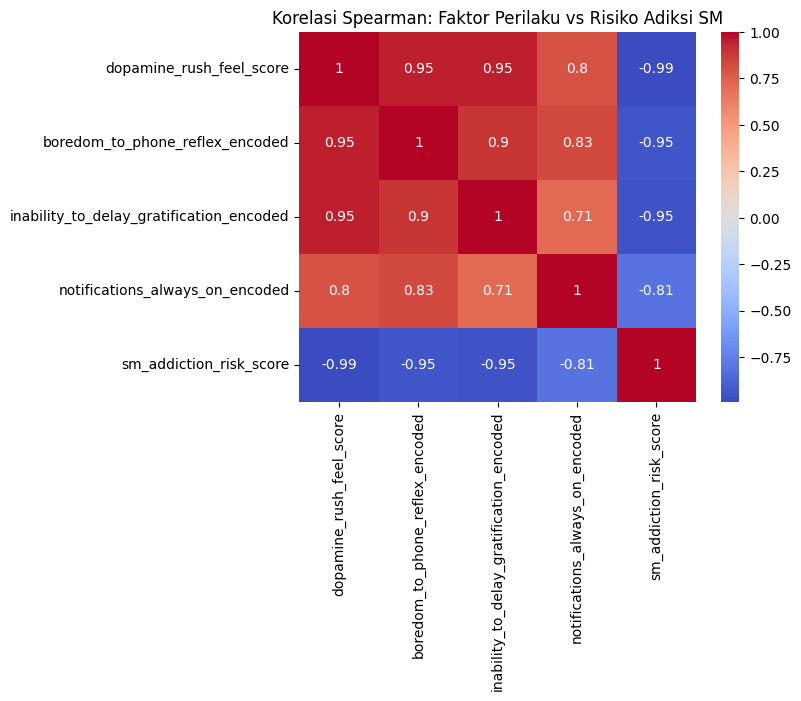

In [ ]:
subset_q6 = df[['dopamine_rush_feel_score', 'boredom_to_phone_reflex', 'inability_to_delay_gratification', 'notifications_always_on', 'sm_addiction_risk_score']].dropna()

mapping_inability_to_delay_gratification = {'Never': 1, 'Rarely': 2, 'Sometimes': 3, 'Yes': 4}
mapping_boredom_to_phone_reflex = {'Never': 1, 'Rarely': 2, 'Sometimes': 3, 'Yes': 4}
mapping_notifications_always_on = {'Yes': 1, 'No': 0}

subset_q6['boredom_to_phone_reflex_encoded'] = subset_q6['boredom_to_phone_reflex'].map(mapping_boredom_to_phone_reflex)
subset_q6['inability_to_delay_gratification_encoded'] = subset_q6['inability_to_delay_gratification'].map(mapping_inability_to_delay_gratification)
subset_q6['notifications_always_on_encoded'] = subset_q6['notifications_always_on'].map(mapping_notifications_always_on)

kolom_q6 = ['dopamine_rush_feel_score', 'boredom_to_phone_reflex_encoded',
            'inability_to_delay_gratification_encoded', 'notifications_always_on_encoded',
            'sm_addiction_risk_score']
matrix_q6 = subset_q6[kolom_q6].corr(method='spearman')
print(matrix_q6)

sns.heatmap(matrix_q6, annot=True, cmap='coolwarm')
plt.title('Korelasi Spearman: Faktor Perilaku vs Risiko Adiksi SM')
plt.show()

**Temuan kritis:** kategori "N/A" (tidak ada gejala) justru memiliki rata-rata
`sm_addiction_risk_score` PALING TINGGI (9.32), sementara kategori dengan gejala
severity spesifik (FOMO, Boredom, dll) memiliki skor rendah (1.4-5.8). Ini
membuktikan skala kolom ini TERBALIK dari makna namanya — nilai tinggi = risiko
RENDAH. Seluruh interpretasi korelasi di bawah ini dibaca dengan koreksi arah ini.

### Kesimpulan Q6

Setelah koreksi arah skala, keempat faktor perilaku (dopamine rush feeling,
boredom-to-phone reflex, inability to delay gratification, notifications always on)
menunjukkan asosiasi POSITIF dengan risiko adiksi sesungguhnya (rho 0.71-0.99
setelah dibalik arahnya), konsisten dengan teori psikologi. Regresi berganda tidak
dijalankan karena multicollinearity ekstrem antar keempat prediktor (0.71-0.95).

## Q7: Apakah digital wellbeing berasosiasi dengan produktivitas dan deep-work?

**Validasi arah skala `digital_wellbeing_score` terlebih dahulu:**

In [ ]:
df.groupby('severity_stage')['digital_wellbeing_score'].mean().sort_values()
print(df[['sm_addiction_risk_score', 'digital_wellbeing_score']].corr(method='spearman'))

In [ ]:
subset_q7 = df[['digital_wellbeing_score', 'deep_work_duration_minutes', 'productivity_self_rating']].dropna()
for col in subset_q7.columns:
    statistic, p_value = stats.shapiro(subset_q7[col])
    print(f"Shapiro-Wilk Statistic {col}: {statistic:.4f}")
    print(f"p-value: {p_value:.4f}")



Shapiro-Wilk Statistic digital_wellbeing_score: 0.9281
p-value: 0.0000
Shapiro-Wilk Statistic deep_work_duration_minutes: 0.9312
p-value: 0.0000
Shapiro-Wilk Statistic productivity_self_rating: 0.9160
p-value: 0.0000


In [ ]:
spearman_matrix = subset_q7.corr(method='spearman')
print(spearman_matrix)

                            digital_wellbeing_score  \
digital_wellbeing_score                    1.000000   
deep_work_duration_minutes                -0.997645   
productivity_self_rating                  -0.981555   

                            deep_work_duration_minutes  \
digital_wellbeing_score                      -0.997645   
deep_work_duration_minutes                    1.000000   
productivity_self_rating                      0.981406   

                            productivity_self_rating  
digital_wellbeing_score                    -0.981555  
deep_work_duration_minutes                  0.981406  
productivity_self_rating                    1.000000  


**Temuan:** `digital_wellbeing_score` JUGA terbalik skalanya — berkorelasi negatif
hampir sempurna (rho=-0.9998) dengan `sm_addiction_risk_score`, mengindikasikan
nilai tinggi = ADA gejala (bukan wellbeing baik). Interpretasi berikut disesuaikan.

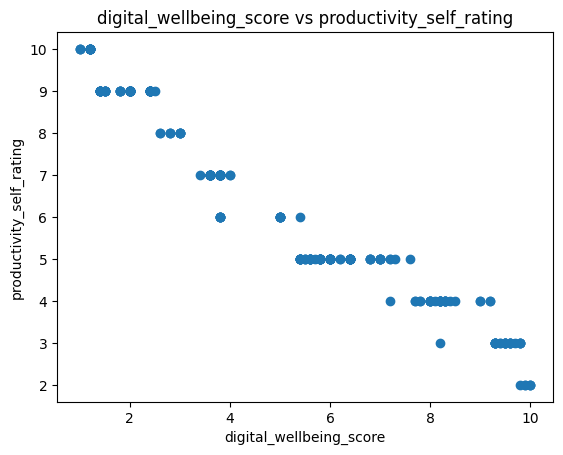

In [ ]:
plt.scatter(subset_q7['digital_wellbeing_score'], subset_q7['productivity_self_rating'])
plt.xlabel('digital_wellbeing_score')
plt.ylabel("productivity_self_rating")
plt.title("digital_wellbeing_score vs productivity_self_rating")
plt.show()

plt.show()

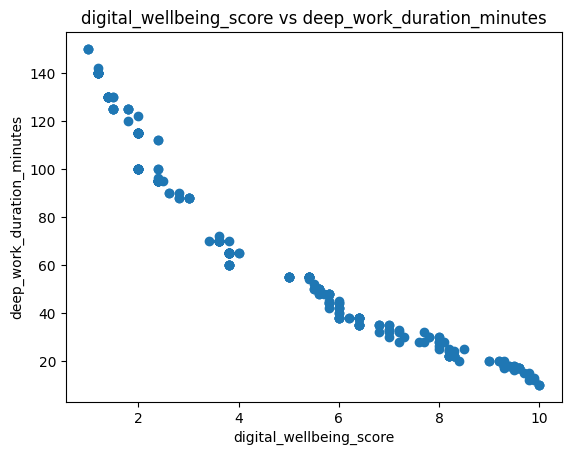

In [ ]:
plt.scatter(subset_q7['digital_wellbeing_score'], subset_q7['deep_work_duration_minutes'])
plt.xlabel('digital_wellbeing_score')
plt.ylabel('deep_work_duration_minutes')
plt.title("digital_wellbeing_score vs deep_work_duration_minutes")
plt.show()

plt.show()

In [ ]:
df.groupby('severity_stage')['productivity_decline_score'].value_counts()

severity_stage         productivity_decline_score
Boredom                None/Minimal                  59
                       Early                         26
                       Severe                        17
                       Moderate                      13
                       Critical                      11
Boredom/Anxiety        Severe                         1
Boredom/Depression     Critical                       1
Comparison             Early                         11
                       Severe                         7
                       Moderate                       5
                       Critical                       2
                       None/Minimal                   2
Comparison/Validation  Critical                       1
Curiosity              Critical                       1
Dopamine rush          Critical                       1
FOMO                   Early                         13
                       Moderate                       7
                       Critical                       3
                       Severe                         3
Gaming/SM combined     Critical                       1
Low motivation         None/Minimal                   3
                       Moderate                       1
N/A                    None/Minimal                  89
Overwhelm              Early                          2
                       None/Minimal                   1
Peer pressure          Early                          1
Perfectionism          Moderate                       3
Validation seeking     Critical                      14
                       Severe                         1
Name: count, dtype: int64

### Kesimpulan Q7

`digital_wellbeing_score` berkorelasi negatif sangat kuat dengan `productivity_self_rating`
(rho=-0.982) dan `deep_work_duration_minutes` (rho=-0.998). Setelah dibaca sesuai
arah data aktual (bukan nama kolom), semakin banyak indikasi masalah penggunaan
media sosial, semakin rendah produktivitas dan deep-work.

## Q8: Dapatkah perilaku media sosial memprediksi penurunan produktivitas?

**Validasi arah skala `productivity_decline_score`:**

In [ ]:
subset_q8 = df[['productivity_decline_score', 'sm_addiction_risk_score']].dropna()

mapping_productivity_decline_score = {'None/Minimal': 0, 'Early': 0, 'Moderate': 1, 'Severe': 1, 'Critical': 1}
productivity_decline_binary = subset_q8['productivity_decline_score'].map(mapping_productivity_decline_score)
subset_q8['productivity_decline_binary'] = productivity_decline_binary

fitur_q8 = ['productivity_decline_binary', 'sm_addiction_risk_score']
print(subset_q8[fitur_q8].corr(method='spearman'))

                             productivity_decline_binary  \
productivity_decline_binary                     1.000000   
sm_addiction_risk_score                        -0.797135   

                             sm_addiction_risk_score  
productivity_decline_binary                -0.797135  
sm_addiction_risk_score                     1.000000  


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


X = subset_q8['sm_addiction_risk_score']
y = subset_q8['productivity_decline_binary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.values.reshape(-1, 1))
X_test_scaled = scaler.transform(X_test.values.reshape(-1, 1))

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = model.score(X_test_scaled, y_test)
print(f"Akurasi Model: {accuracy * 100:.2f}%")

Akurasi Model: 93.33%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[44  0]
 [ 4 12]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        44
           1       1.00      0.75      0.86        16

    accuracy                           0.93        60
   macro avg       0.96      0.88      0.91        60
weighted avg       0.94      0.93      0.93        60



### Kesimpulan Q8

Model Logistic Regression dengan fitur tunggal `sm_addiction_risk_score` mencapai
akurasi 93% (baseline 69%). Precision kelas "decline" sempurna (100%), namun
recall 75% — model konservatif, melewatkan 25% kasus penurunan produktivitas
sesungguhnya. Fitur lain (avg_daily_sm_hours, doomscrolling_frequency) tidak
disertakan karena multicollinearity ekstrem (0.96-0.99) dengan sm_addiction_risk_score.